# SMOTE reproduction (Chawla et al., JAIR 2002, Table 3)

This notebook reproduces the main experiment of the SMOTE paper: the AUC of a decision tree trained with
**plain majority undersampling** versus **SMOTE plus undersampling**, using stratified 10 fold cross validation.

What the notebook does, from top to bottom:
1. sets the parameters,
2. implements SMOTE and the undersampling rule from scratch (pseudocode of Sections 4.2 and 4.3 of the paper) and tests them,
3. downloads four of the paper's datasets (Pima, Phoneme, Oil, Mammography),
4. runs the experiment,
5. prints the comparison table (paper versus this reproduction) and draws the ROC curves.

**How to run:** `Run all` in Jupyter or Google Colab. It needs `numpy>=2`, `pandas`, `scikit-learn` and `matplotlib`, and an
internet connection for the data download. A full run (3 repeats) takes about 8 to 11 minutes on one CPU core, depending on the machine.
Set `REPEATS = 1` in the next cell for a quick run.

In [1]:
import os, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier

## 1. Parameters
All values follow the paper unless noted. The paper used C4.5 release 8; scikit-learn has no C4.5, so an unpruned
entropy decision tree with a minimum leaf size of 2 is used as a stand in.

In [2]:
REPEATS = 3                                   # repeats of 10 fold CV with different fold splits (the paper reports one run)
DATASETS = ["pima", "phoneme", "oil", "mammography"]

K = 5                                         # nearest neighbours used by SMOTE (paper)
SMOTE_LEVELS = [50, 100, 200, 300, 400, 500]  # amount of SMOTE in percent (paper)
UNDER_LEVELS = [None, 10, 15, 25, 50, 75, 100, 125, 150, 175, 200,
                300, 400, 500, 600, 700, 800, 1000, 2000]   # majority undersampling in percent; None = raw data point (paper)
FOLDS = 10                                    # stratified cross validation (paper: 10 fold)
TREE = dict(criterion="entropy", min_samples_leaf=2)        # stand in for C4.5, unpruned, hard class labels

DATA_DIR = "data"
BASE_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
FILES = {"pima": "pima-indians-diabetes.csv", "phoneme": "phoneme.csv",
         "oil": "oil-spill.csv", "mammography": "mammography.csv"}
NAMES = {"pima": "Pima", "phoneme": "Phoneme", "oil": "Oil", "mammography": "Mammography"}

# AUC values of Table 3 of the paper (C4.5), divided by 10000. Cells the paper does not report are left out.
PAPER = {
    "pima":        {"Under": .7242, 100: .7307},
    "phoneme":     {"Under": .8622, 100: .8644, 200: .8661},
    "oil":         {"Under": .8524, 100: .8523, 200: .8368, 300: .8161, 400: .8339, 500: .8537},
    "mammography": {"Under": .9260, 100: .9250, 200: .9265, 300: .9311, 400: .9330, 500: .9304},
}

## 2. SMOTE and undersampling (own implementation)
`smote` follows the pseudocode of the paper: for every minority sample a random one of its `k` nearest minority neighbours is chosen,
and a synthetic point is placed at a random position on the line segment between the two. The amount `N` is given in percent
(multiples of 100; for `N < 100` only a random subset of the minority samples is used as seeds).

`undersample_majority` uses the paper's definition: undersampling at 200 percent means the data holds twice as many minority as
majority samples, so `n_majority = n_minority / (pct / 100)`.

In [3]:
def smote(X_min, N=100, k=5, rng=None):
    """Return (N/100) * T synthetic samples built from the T minority samples X_min."""
    rng = np.random.default_rng(rng)
    T = len(X_min)
    if N < 100:
        X_src = X_min[rng.permutation(T)[: int(round(N / 100 * T))]]
        N = 100
    else:
        X_src = X_min
    n_rep = int(N // 100)
    k_eff = min(k, T - 1)
    nn = NearestNeighbors(n_neighbors=k_eff + 1).fit(X_min)
    nn_idx = nn.kneighbors(X_src, return_distance=False)[:, 1:]      # drop the sample itself
    synth = np.empty((len(X_src) * n_rep, X_min.shape[1]))
    row = 0
    for i in range(len(X_src)):
        for _ in range(n_rep):
            j = nn_idx[i, rng.integers(k_eff)]                       # one of the k neighbours
            gap = rng.random()                                       # random number in [0, 1)
            synth[row] = X_src[i] + gap * (X_min[j] - X_src[i])
            row += 1
    return synth


def undersample_majority(X_maj, n_min_total, pct, rng=None):
    """Randomly keep n_min_total / (pct / 100) majority samples. pct=None keeps all of them."""
    rng = np.random.default_rng(rng)
    if pct is None:
        return X_maj
    n_keep = max(1, min(int(round(n_min_total / (pct / 100.0))), len(X_maj)))
    return X_maj[rng.permutation(len(X_maj))[:n_keep]]


def build_training_set(X_tr, y_tr, smote_pct, under_pct, k=5, rng=None):
    """Optionally SMOTE the minority class (label 1), then optionally undersample the majority class (label 0)."""
    rng = np.random.default_rng(rng)
    X_min, X_maj = X_tr[y_tr == 1], X_tr[y_tr == 0]
    parts = [X_min] + ([smote(X_min, N=smote_pct, k=k, rng=rng)] if smote_pct else [])
    X_min_all = np.vstack(parts)
    X_maj_use = undersample_majority(X_maj, len(X_min_all), under_pct, rng)
    X = np.vstack([X_min_all, X_maj_use])
    y = np.r_[np.ones(len(X_min_all), int), np.zeros(len(X_maj_use), int)]
    return X, y

### Tests of the implementation
Checks that the number of synthetic samples is `N/100 * T`, that every synthetic point lies on a line segment between a minority
sample and one of its 5 nearest minority neighbours, the worked example from the paper's Table 1, and the undersampling example
of Section 4.3 (50 minority, 200 majority, 200 percent gives 25 majority samples).

In [4]:
def self_test():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(60, 4))
    for N in (100, 200, 500):
        assert len(smote(X, N=N, rng=1)) == N // 100 * len(X)
    assert len(smote(X, N=50, rng=1)) == 30
    S = smote(X, N=300, k=5, rng=2)
    nn = NearestNeighbors(n_neighbors=6).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    for s in S:
        ok = False
        for i in range(len(X)):
            for j in nn[i]:
                d = X[j] - X[i]
                t = np.dot(s - X[i], d) / np.dot(d, d)
                if -1e-9 <= t <= 1 + 1e-9 and np.allclose(X[i] + t * d, s):
                    ok = True
                    break
            if ok:
                break
        assert ok
    P = np.array([[6., 4.], [4., 3.]])                     # Table 1 of the paper: sample (6,4), neighbour (4,3)
    Sx = smote(P, N=1000, k=1, rng=3)
    t = (Sx[:, 0] - 6) / -2
    assert np.allclose(Sx[:, 1], 4 - t) and (t >= 0).all() and (t <= 1).all()
    assert len(undersample_majority(np.zeros((200, 2)), 50, 200)) == 25
    print("all tests passed")

self_test()

all tests passed


## 3. Data
Public copies of four of the paper's datasets are downloaded into `./data` (only if they are not there yet). The minority class is
label 1: diabetes (Pima), oral sounds (Phoneme), oil spill (Oil), calcification (Mammography). For Oil the first column (patch id) is dropped.
The class counts are compared with Table 2 of the paper.

In [5]:
def load(name):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, FILES[name])
    if not os.path.exists(path):
        print("downloading", FILES[name])
        urllib.request.urlretrieve(BASE_URL + FILES[name], path)
    df = pd.read_csv(path, header=None)
    if name == "oil":
        df = df.iloc[:, 1:]
    X = df.iloc[:, :-1].values.astype(float)
    last = df.iloc[:, -1]
    y = last.astype(str).str.contains("'1'").values.astype(int) if name == "mammography" else last.values.astype(int)
    return X, y

PAPER_COUNTS = {"pima": (500, 268), "phoneme": (3818, 1586), "oil": (896, 41), "mammography": (10923, 260)}  # Table 2
rows = []
for name in DATASETS:
    X, y = load(name)
    rows.append(dict(dataset=NAMES[name], majority=int((y == 0).sum()), minority=int(y.sum()), features=X.shape[1],
                     matches_paper=(int((y == 0).sum()), int(y.sum())) == PAPER_COUNTS[name]))
pd.DataFrame(rows)

downloading pima-indians-diabetes.csv
downloading phoneme.csv
downloading oil-spill.csv
downloading mammography.csv


,dataset,majority,minority,features,matches_paper
0,Pima,500,268,8,True
1,Phoneme,3818,1586,5,True
2,Oil,896,41,48,True
3,Mammography,10923,260,6,True


## 4. Experiment
For every dataset, the ROC curve of plain undersampling ("Under") and one ROC curve per SMOTE level are built. Each ROC point is the
mean false positive and true positive rate over the 10 folds. Resampling is applied to the training folds only. The AUC is the
trapezoid area with the points (0,0) and (1,1) added. The ROC convex hull is used to count which curve contributes more potentially
optimal classifiers, as in the paper.

In [6]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

def one_fold(X, y, tr, te, smote_pct, under_pct, seed):
    Xs, ys = build_training_set(X[tr], y[tr], smote_pct, under_pct, k=K, rng=seed)
    pred = DecisionTreeClassifier(random_state=seed, **TREE).fit(Xs, ys).predict(X[te])
    yt = y[te]
    tp = ((pred == 1) & (yt == 1)).sum() / max(1, (yt == 1).sum())
    fp = ((pred == 1) & (yt == 0)).sum() / max(1, (yt == 0).sum())
    return tp, fp

def roc_points(X, y, smote_pct, repeat):
    """One ROC curve: mean (FP, TP) over the folds for every undersampling level."""
    splits = list(StratifiedKFold(FOLDS, shuffle=True, random_state=repeat).split(X, y))
    pts = []
    for u in UNDER_LEVELS:
        res = [one_fold(X, y, tr, te, smote_pct, u, seed=1000 * repeat + i) for i, (tr, te) in enumerate(splits)]
        tp, fp = np.mean(res, axis=0)
        pts.append((fp, tp))
    return pts

def auc_anchored(pts):
    p = np.array(sorted(pts + [(0.0, 0.0), (1.0, 1.0)]))
    return _trapz(p[:, 1], p[:, 0])

def hull_share(curve_a, curve_b):
    """Number of points of each curve on the upper ROC convex hull of both curves together."""
    pts = [(fp, tp, "A") for fp, tp in curve_a] + [(fp, tp, "B") for fp, tp in curve_b]
    pts += [(0.0, 0.0, "-"), (1.0, 1.0, "-")]
    pts = sorted(pts, key=lambda t: (t[0], -t[1]))
    hull = []
    for p in pts:
        while len(hull) >= 2:
            (x1, y1, _), (x2, y2, _) = hull[-2], hull[-1]
            if (x2 - x1) * (p[1] - y1) - (y2 - y1) * (p[0] - x1) >= 0:
                hull.pop()
            else:
                break
        hull.append(p)
    return sum(h[2] == "A" for h in hull), sum(h[2] == "B" for h in hull)

def run_dataset(name):
    X, y = load(name)
    runs = []
    for r in range(REPEATS):
        curves = {"Under": roc_points(X, y, None, r)}
        for s in SMOTE_LEVELS:
            curves[f"SMOTE {s}%"] = roc_points(X, y, s, r)
        runs.append(curves)
    return runs

def summarise(runs):
    keys = list(runs[0].keys())
    auc = {k: [auc_anchored(r[k]) for r in runs] for k in keys}
    mean = {k: float(np.mean(v)) for k, v in auc.items()}
    sd = {k: float(np.std(v, ddof=1)) if len(v) > 1 else 0.0 for k, v in auc.items()}
    mean_pts = {k: [tuple(np.mean([r[k][i] for r in runs], axis=0)) for i in range(len(runs[0][k]))] for k in keys}
    best = max(keys[1:], key=lambda k: mean[k])
    return dict(mean=mean, sd=sd, best=best, hull=hull_share(mean_pts[best], mean_pts["Under"]),
                curves=(mean_pts["Under"], mean_pts[best]))

In [7]:
results = {}
for name in DATASETS:
    t = time.time()
    results[name] = summarise(run_dataset(name))
    print(f"{NAMES[name]}: done in {time.time() - t:.0f}s")

Pima: done in 87s
Phoneme: done in 466s
Oil: done in 51s
Mammography: done in 82s


## 5. Results
AUC per dataset and setting. `paper` is Table 3 of the paper, `ours` the mean over the repeats and `sd` the standard deviation between
repeats. `n/a` means the paper reports no value for that cell.

In [8]:
cols = ["Under"] + [f"SMOTE {s}%" for s in SMOTE_LEVELS]
paper_val = lambda name, c: PAPER[name].get("Under" if c == "Under" else int(c.split()[1].rstrip("%")))
table = []
for name, res in results.items():
    table.append([NAMES[name], "paper"] + [paper_val(name, c) if paper_val(name, c) is not None else np.nan for c in cols])
    table.append(["", "ours"] + [res["mean"][c] for c in cols])
    table.append(["", "sd"] + [res["sd"][c] for c in cols])
table = pd.DataFrame(table, columns=["dataset", ""] + [c.replace("SMOTE ", "S") for c in cols])
table.style.format({c: "{:.4f}" for c in table.columns[2:]}, na_rep="n/a").hide(axis="index")

dataset,,Under,S50%,S100%,S200%,S300%,S400%,S500%
Pima,paper,0.7242,n/a,0.7307,n/a,n/a,n/a,n/a
,ours,0.7251,0.7158,0.7207,0.7205,0.7068,0.6989,0.7069
,sd,0.0016,0.0041,0.0099,0.0133,0.0173,0.0108,0.0005
Phoneme,paper,0.8622,n/a,0.8644,0.8661,n/a,n/a,n/a
,ours,0.8961,0.8944,0.8949,0.8980,0.8918,0.8912,0.8924
,sd,0.0026,0.0020,0.0027,0.0011,0.0047,0.0003,0.0002
Oil,paper,0.8524,n/a,0.8523,0.8368,0.8161,0.8339,0.8537
,ours,0.8119,0.8095,0.8275,0.8190,0.8330,0.8345,0.8289
,sd,0.0083,0.0242,0.0180,0.0226,0.0154,0.0383,0.0092
Mammography,paper,0.9260,n/a,0.9250,0.9265,0.9311,0.9330,0.9304


In [9]:
summary = []
for name, res in results.items():
    best = res["best"]
    paper_best = max(v for k, v in PAPER[name].items() if k != "Under")
    summary.append(dict(dataset=NAMES[name], best_smote_level=best,
                        AUC_under=res["mean"]["Under"], AUC_best_smote=res["mean"][best],
                        gain_ours=res["mean"][best] - res["mean"]["Under"],
                        gain_paper=paper_best - PAPER[name]["Under"],
                        hull_points_smote=res["hull"][0], hull_points_under=res["hull"][1]))
summary = pd.DataFrame(summary)
summary.style.format({"AUC_under": "{:.4f}", "AUC_best_smote": "{:.4f}", "gain_ours": "{:+.4f}", "gain_paper": "{:+.4f}"}).hide(axis="index")

dataset,best_smote_level,AUC_under,AUC_best_smote,gain_ours,gain_paper,hull_points_smote,hull_points_under
Pima,SMOTE 100%,0.7251,0.7207,-0.0043,+0.0065,2,4
Phoneme,SMOTE 200%,0.8961,0.8980,+0.0019,+0.0039,7,2
Oil,SMOTE 400%,0.8119,0.8345,+0.0226,+0.0013,3,2
Mammography,SMOTE 50%,0.9164,0.9193,+0.0029,+0.0070,5,3


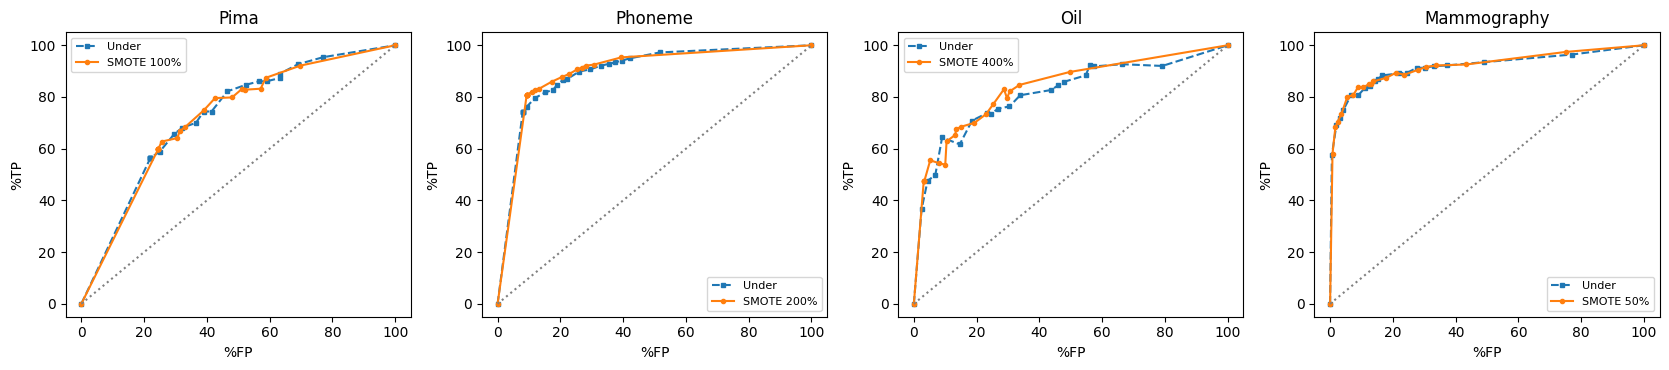

In [10]:
fig, axs = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.8))
for ax, (name, res) in zip(np.atleast_1d(axs), results.items()):
    for pts, lab, st in ((res["curves"][0], "Under", "s--"), (res["curves"][1], res["best"], "o-")):
        p = np.array(sorted(pts + [(0, 0), (1, 1)]))
        ax.plot(p[:, 0] * 100, p[:, 1] * 100, st, ms=3, label=lab)
    ax.plot([0, 100], [0, 100], ":", c="grey")
    ax.set_title(NAMES[name]); ax.set_xlabel("%FP"); ax.set_ylabel("%TP"); ax.legend(fontsize=8)
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/roc_curves.png", dpi=160)
table.to_csv("results/table_auc.csv", index=False)
plt.show()

## 6. Notes on differences from the paper
* **Classifier:** the paper used C4.5 release 8 (pruned). An unpruned scikit-learn entropy tree is used here, so decision regions and ROC points differ.
* **Data:** the files are public copies, not necessarily the authors' versions. Only 4 of the 8 datasets of Table 3 are covered
  (E-state and Can came from the authors' own sources, see Section 5.1; Satimage and Forest Cover were not included, because they need extra preparation into two classes and Forest Cover is very large). Ripper and Naive Bayes are not reproduced.
* **AUC:** anchored at (0,0) and (1,1). The paper takes the raw data point as the leftmost point and adds (1,1), which gives lower values (not computed in this notebook; in a separate check, Pima undersampling gave 0.663 instead of 0.725).
* **Undersampling:** it is assumed that the minority count used in the undersampling rule includes the synthetic samples.
* **Randomness:** the paper reports one run. Here the mean and standard deviation over `REPEATS` repeated 10 fold splits are shown, and the best
  SMOTE level is picked per dataset (as in the paper), which favours SMOTE. The gains over plain undersampling are about as large as the
  spread between repeats, so they should not be read as significant.